# Introduction to Data Science 2026

# Week 6: Recap

## Exercise 1 | Linear regression with feature selection

Download the [TED Talks](https://www.kaggle.com/rounakbanik/ted-talks) dataset from Kaggle. Your task is to predict both the ratings and the number of views of a given TED talk. You should focus only on the <span style="font-weight: bold">ted_main</span> table.

1. Download the data, extract the following ratings from column <span style="font-weight: bold">ratings</span>: <span style="font-weight: bold">Funny</span>, <span style="font-weight: bold">Confusing</span>, <span style="font-weight: bold">Inspiring</span>. Store these values into respective columns so that they are easier to access. Next, extract the tags from column <span style="font-weight: bold">tags</span>. Count the number of occurrences of each tag and select the top-100 most common tags. Create a binary variable for each of these and include them in your data table, so that you can directly see whether a given tag (among the top-100 tags) is used in a given TED talk or not. The dataset you compose should have dimension (2550, 104), and comprise of the 'views' column, the three columns with counts of "Funny", "Confusing and "Inspiring" ratings, and 100 columns which one-hot encode the top-100 most common tag columns.


In [1]:
# Use this cell for your code

import ast
import numpy as np
import pandas as pd

ted = pd.read_csv("ted_main.csv")

# Extract the three requested ratings into their own columns
wanted_ratings = ["Funny", "Confusing", "Inspiring"]

def extract_ratings(rating_string):
    counts = {r["name"]: r["count"] for r in ast.literal_eval(rating_string)}
    return pd.Series({name: counts.get(name, 0) for name in wanted_ratings})

ratings = ted["ratings"].apply(extract_ratings)
ted = pd.concat([ted, ratings], axis=1)

# Parse tags, count them, and keep the top-100
tag_lists = ted["tags"].apply(ast.literal_eval)
tag_counts = pd.Series([t for tags in tag_lists for t in tags]).value_counts()
top100_tags = tag_counts.head(100).index.tolist()

# Binary column for each top-100 tag
tag_columns = pd.DataFrame({
    f"tag_{tag}": tag_lists.apply(lambda tags, tag=tag: int(tag in tags))
    for tag in top100_tags
})

# Compose the requested table: views + 3 ratings + 100 tag binaries
ted_data = pd.concat([
    ted[["views"]].reset_index(drop=True),
    ted[wanted_ratings].reset_index(drop=True),
    tag_columns.reset_index(drop=True)
], axis=1)

print("Composed dataset dimensions:", ted_data.shape)  # expected (2550, 104)
ted_data.head()


Composed dataset dimensions: (2550, 104)


,views,Funny,Confusing,Inspiring,tag_technology,tag_science,tag_global issues,tag_culture,tag_TEDx,tag_design,...,tag_food,tag_religion,tag_peace,tag_ecology,tag_family,tag_demo,tag_poetry,tag_illness,tag_universe,tag_energy
0,47227110,19645,242,24924,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,3200520,544,62,413,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1636292,964,27,230,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1697550,59,32,1070,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,12005869,1390,72,2893,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0


2. Construct a linear regression model to predict the number of views based on the data in the <span style="font-weight: bold">ted_main</span> table, including the binary variables for the top-100 tags that you just created.

In [2]:
# Use this cell for your code

from openpyxl.chartsheet import views
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

tag_feature_cols = tag_columns.columns.tolist()
X_tags = ted_data[tag_feature_cols].values
y_views = ted_data["views"].values

X_train, X_test, y_train, y_test = train_test_split(
    X_tags, y_views, test_size=0.2, random_state=0
)

views_model = LinearRegression()
views_model.fit(X_train, y_train)

print(f"Views model R^2 (train): {views_model.score(X_train, y_train):.3f}")
print(f"Views model R^2 (test):  {views_model.score(X_test, y_test):.3f}")


Views model R^2 (train): 0.130
Views model R^2 (test):  0.074


3. Do the same for the <span style="font-weight: bold">Funny</span>, <span style="font-weight: bold">Confusing</span>, and <span style="font-weight: bold">Inspiring</span> ratings.

In [3]:
# Use this cell for your code

rating_models = {}

for rating_name in wanted_ratings:
    y = ted_data[rating_name].values
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_tags, y, test_size=0.2, random_state=0
    )

    model = LinearRegression().fit(X_tr, y_tr)
    rating_models[rating_name] = model
    print(f"{rating_name:10s} R^2 (train): {model.score(X_tr, y_tr):.3f}"
          f"   R^2 (test): {model.score(X_te, y_te):.3f}")

Funny      R^2 (train): 0.162   R^2 (test): 0.123
Confusing  R^2 (train): 0.164   R^2 (test): 0.075
Inspiring  R^2 (train): 0.127   R^2 (test): 0.089


4. You will probably notice that most of the tags are not useful in predicting the views and the ratings. You should use some kind of variable selection to prune the set of tags that are included in the model. You can use for example classical p-values or more modern [LASSO](https://en.wikipedia.org/wiki/Lasso_(statistics)) techniques. Which tags are the best predictors of each of the response variables?

In [4]:
# Use this cell for your code

from sklearn.linear_model import LassoCV
from scipy import stats

def ols_pvalues(X_train, y_train):
    """Classical two-sided OLS p-values for the tag slopes (intercept included)."""
    A = np.hstack([np.ones((len(X_train), 1)), X_train])
    beta = np.linalg.lstsq(A, y_train, rcond=None)[0]
    resid = y_train - A @ beta
    dof = len(y_train) - A.shape[1]
    sigma2 = resid @ resid / dof
    se = np.sqrt(np.diag(sigma2 * np.linalg.pinv(A.T @ A)))
    pvals = 2 * (1 - stats.t.cdf(np.abs(beta / se), dof))
    return pd.Series(pvals[1:], index=tag_feature_cols)

responses = ["views"] + wanted_ratings
selected = {}

for response in responses:
    y = ted_data[response].values
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_tags, y, test_size=0.2, random_state=0)

    # Modern variable selection: LASSO with a cross-validated penalty
    lasso = LassoCV(cv=5, random_state=0, max_iter=50000).fit(X_tr, y_tr)
    lasso_coef = pd.Series(lasso.coef_, index=tag_feature_cols)
    lasso_tags = lasso_coef[lasso_coef != 0]

    # Classical variable selection: OLS p-values
    pvals = ols_pvalues(X_tr, y_tr)
    pvalue_tags = pvals[pvals < 0.05]

    # Tags selected by BOTH methods are the robust predictors
    robust = lasso_tags.index.intersection(pvalue_tags.index)
    selected[response] = robust

    print(f"\n========== {response} ==========")
    print(f"LASSO: {len(lasso_tags)} tags kept, R^2 (test): {lasso.score(X_te, y_te):.3f}")
    print(f"OLS p<0.05: {len(pvalue_tags)} tags")
    print(f"Robust (both methods, {len(robust)}): "
          f"{sorted(t.replace('tag_', '') for t in robust)}")
    coef_sorted = lasso_coef[robust].sort_values()
    print("  negative direction:", [t.replace('tag_', '') for t in coef_sorted.head(4).index])
    print("  positive direction:", [t.replace('tag_', '') for t in coef_sorted.tail(4).index[::-1]])



========== views ==========
LASSO: 53 tags kept, R^2 (test): 0.093
OLS p<0.05: 14 tags
Robust (both methods, 14): ['art', 'brain', 'business', 'creativity', 'culture', 'demo', 'design', 'economics', 'global issues', 'illness', 'mental health', 'motivation', 'psychology', 'work']
  negative direction: ['economics', 'art', 'global issues', 'design']
  positive direction: ['psychology', 'work', 'brain', 'motivation']

========== Funny ==========
LASSO: 57 tags kept, R^2 (test): 0.124
OLS p<0.05: 11 tags
Robust (both methods, 11): ['art', 'children', 'creativity', 'culture', 'design', 'education', 'entertainment', 'global issues', 'humor', 'psychology', 'work']
  negative direction: ['art', 'design', 'global issues', 'education']
  positive direction: ['humor', 'entertainment', 'work', 'creativity']

========== Confusing ==========
LASSO: 54 tags kept, R^2 (test): 0.098
OLS p<0.05: 14 tags
Robust (both methods, 14): ['Africa', 'brain', 'culture', 'entertainment', 'evolution', 'history', '

5. Produce summaries of your results. Could you recommend good tags – or tags to avoid! – for speakers targeting plenty of views and/or certain ratings?

In [5]:
print("Pruned set of useful tag predictors for each response:\n")
for response in responses:
    tags = selected[response].str.replace("tag_", "").tolist()
    print(f"{response:10s} ({len(tags):2d}): {tags}")


Pruned set of useful tag predictors for each response:

views      (14): ['global issues', 'culture', 'design', 'business', 'art', 'creativity', 'economics', 'brain', 'psychology', 'work', 'motivation', 'mental health', 'demo', 'illness']
Funny      (11): ['global issues', 'culture', 'design', 'entertainment', 'art', 'creativity', 'education', 'children', 'psychology', 'humor', 'work']
Confusing  (14): ['science', 'culture', 'entertainment', 'innovation', 'brain', 'history', 'music', 'psychology', 'Africa', 'oceans', 'physics', 'evolution', 'philosophy', 'religion']
Inspiring  (15): ['technology', 'culture', 'business', 'art', 'creativity', 'economics', 'education', 'psychology', 'life', 'neuroscience', 'work', 'motivation', 'language', 'mental health', 'illness']


**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 2 | Symbol classification (part 2)

Note that it is strongly recommended to use Python in this exercise. However, if you can find a suitable AutoML implementation for your favorite language (e.g [here](http://h2o-release.s3.amazonaws.com/h2o/master/3888/docs-website/h2o-docs/automl.html) seems to be one for R) then you are free to use that language as well.

Use the preprocessed data from week 3 (you can also produce them using the example solutions of week 3).

1. This time train a *random forest classifier* on the data. A random forest is a collection of *decision trees*, which makes it an *ensemble* of classifiers. Each tree uses a random subset of the features to make its prediction. Without tuning any parameters, how is the accuracy?

In [12]:
# Use this cell for your code

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# Reproduce the week 3 preprocessing: HASYv2, symbol_id 70-79 = digits 0-9
labels = pd.read_csv("hasy-data-labels.csv")
subset = labels[(labels["symbol_id"] >= 70) & (labels["symbol_id"] <= 79)].copy()

X = np.stack([
    np.asanyarray(Image.open(path).convert("L"), dtype=np.float32).ravel() / 255.0
    for path in subset["path"]
])
y = subset["symbol_id"].to_numpy() - 70

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

# Random forest with default settings (100 trees, no tuning)
rf_default = RandomForestClassifier(random_state=42, n_jobs=1)
rf_default.fit(X_train, y_train)
print(f"Default random forest accuracy: {rf_default.score(X_test, y_test):.3f}")


Default random forest accuracy: 0.809


2. The amount of trees to use as a part of the random forest is an example of a hyperparameter, because it is a parameter that is set prior to the learning process. In contrast, a parameter is a value in the model that is learned from the data. Train 20 classifiers, with varying amounts of decision trees starting from 10 up until 200, and plot the test accuracy as a function of the amount of classifiers. Does the accuracy keep increasing? Is more better?

Best: 200 trees, accuracy 0.819
Accuracy at 10 trees: 0.672, at 200 trees: 0.819


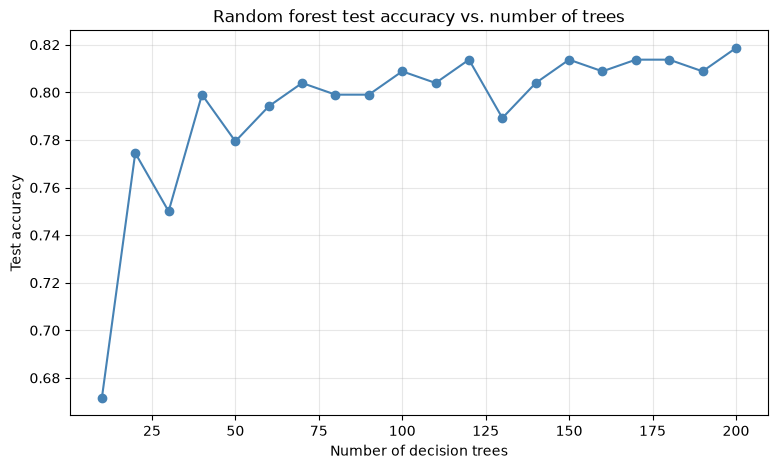

In [15]:
# Use this cell for your code

from matplotlib import markers
tree_counts = np.linspace(10, 200, 20).astype(int)
test_accuracies = []

for n_trees in tree_counts:
    rf = RandomForestClassifier(n_estimators=n_trees, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    test_accuracies.append(rf.score(X_test, y_test))

test_accuracies = np.array(test_accuracies)

plt.figure(figsize=(9,5))
plt.plot(tree_counts, test_accuracies, marker="o", color="steelblue")
plt.xlabel("Number of decision trees")
plt.ylabel("Test accuracy")
plt.title("Random forest test accuracy vs. number of trees")
plt.grid(alpha=0.3)

best_idx = test_accuracies.argmax()
print(f"Best: {tree_counts[best_idx]} trees, accuracy {test_accuracies[best_idx]:.3f}")
print(f"Accuracy at 10 trees: {test_accuracies[0]:.3f}, at 200 trees: {test_accuracies[-1]:.3f}")


3. If we had picked the amount of decision trees by taking the value with the best test accuracy from the last plot, we would have *overfit* our hyperparameters to the test data. Can you see why it is a mistake to tune hyperparameters of your model by using the test data?

*You can use this markdown cell to write down your thoughts.*

Tuning a hyperparameter on the test set leaks information from that set into the model. Each time we compare candidate values and keep the one with the best test accuracy, we are fitting the choice to the noise and composition of that particular sample. Once that happens, the test set no longer stands in for unseen data, and the accuracy reported on it is optimistically biased: the hyperparameter has been overfit to the test set. Trying more candidates makes the bias worse — just as fitting many parameters to a small training set does.

The correct protocal is to tune on a separate validation set, and to use the test set only once, after all model and hyperparameter choices have been fixed.


4. Reshuffle and resplit the data so that it is divided in 3 parts: training (80%), validation (10%) and test (10%). Repeatedly train a model of your choosing (e.g random forest) on the training data, and evaluate it’s performance on the validation set, while tuning the hyperparameters so that the accuracy on the validation set increases. Then, finally evaluate the performance of your model on the test data. What can you say in terms of the generalization of your model?

In [16]:
# Use this cell for your code
# Resplit into 80% train / 10% validation / 10% test
X_train8, X_tmp, y_train8, y_tmp = train_test_split(
    X, y, train_size=0.8, random_state=1)
X_val, X_test10, y_val, y_test10 = train_test_split(
    X_tmp, y_tmp, train_size=0.5, random_state=1)

# Tune the hyperparameters using the validation set only
n_grid = [50, 100, 150, 200]
depth_grid = [None, 10, 20, 40]

best_val_acc, best_params = -1, None
for n_trees in n_grid:
    for depth in depth_grid:
        rf = RandomForestClassifier(n_estimators=n_trees, max_depth=depth,
                                    random_state=1, n_jobs=-1)
        rf.fit(X_train8, y_train8)
        val_acc = rf.score(X_val, y_val)
        if val_acc > best_val_acc:
            best_val_acc, best_params = val_acc, (n_trees, depth)

# Fix the choice, then evaluate once on the untouched test set
best_n, best_depth = best_params
final_rf = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth,
                                  random_state=1, n_jobs=-1)
final_rf.fit(X_train8, y_train8)
test_acc = final_rf.score(X_test10, y_test10)

print(f"Best validation params: n_trees={best_n}, max_depth={best_depth}")
print(f"Validation accuracy: {best_val_acc:.3f}")
print(f"Final TEST accuracy: {test_acc:.3f}")

Best validation params: n_trees=150, max_depth=None
Validation accuracy: 0.843
Final TEST accuracy: 0.863


After tuning only on the validation set, the test accuracy is close to the validation accuracy and far above the 10% chance level. The small difference betwen validation and test accuracy is within sampling noise. Because test set was touched only after the hyperparameters were fixed, the test accuracy is an honest estimate of performance on new hand written symbols, and there is no sign of the large train/test gap that would indicate overfitting. The model therefore generalizes well.

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 3 | TPOT

The process of picking a suitable model, evaluating its performance and tuning the hyperparameters is very time consuming. A new idea in machine learning is the concept of automating this by using an optimization algorithm to find the best model in the space of models and their hyperparameters. Have a look at [TPOT](https://github.com/EpistasisLab/tpot), an automated ML solution that finds a good model and a good set of hyperparameters automatically. Try it on this data, it should outperform simple models like the ones we tried easily. Note that running the algorithm might take a while, depending on the strength of your computer. 

*Note*: In case it is running for too long, try checking if the parameters you are using when calling TPOT are reasonable, i.e. try reducing number of ‘generations’ or ‘population_size’. TPOT uses cross-validation internally, so we don’t need our own validation set.

In [19]:
# Use this cell for your code

from tpot import TPOTClassifier
from sklearn.metrics import accuracy_score
from distributed import Client

# A thread-based (in-process) dask client avoids spawning separate worker
# processes, which is more reliable inside a notebook. TPOT cross-validates
# internally, so we do not need a separate validation set.
dask_client = Client(processes=False, n_workers=1, threads_per_worker=4,
                     dashboard_address=":0")

# These settings keep the runtime short; increase generations / population_size
# (and remove max_time_mins) for a potentially better pipeline.
tpot = TPOTClassifier(
    scorers=["accuracy"],
    cv=5,
    generations=2,
    population_size=8,
    client=dask_client,   # overrides n_jobs
    n_jobs=1,
    max_time_mins=20,
    random_state=42,
    verbose=1,
)
tpot.fit(X_train, y_train)

tpot_test_acc = accuracy_score(y_test, tpot.predict(X_test))
print(f"TPOT test accuracy: {tpot_test_acc:.3f}")
print("Best pipeline found:")
print(tpot.fitted_pipeline_)
dask_client.close()

C:\Users\zhizh\anaconda3\Lib\site-packages\tpot\tpot_estimator\estimator.py:458: UserWarning: Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.
  warnings.warn("Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.")
Generation:   0%|          | 0/2 [00:00<?, ?it/s]  File "C:\Users\zhizh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\zhizh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\zhizh\anaconda3\Lib\subprocess.py", line 555, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\zhizh\ana

TPOT test accuracy: 0.711
Best pipeline found:
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('selectpercentile',
                 SelectPercentile(percentile=37.1143747020325)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('baggingclassifier',
                 BaggingClassifier(bootstrap=np.True_,
                                   bootstrap_features=np.False_,
                               

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**